# 03b — BSADF en ventana móvil: nueva base del semáforo

**Capa 3 — Procesamiento** · Metodología vigente del semáforo

**Decisión de diseño:** reemplazar el SADF anclado al inicio de la serie por un **test BSADF en ventana móvil de 260 semanas** (versión acotada del GSADF de Phillips, Shi y Yu, 2015).

**Motivo** (notebook 03, sección 6): con ventanas ancladas en 1995 el umbral rojo es casi inalcanzable (ADF máximo de NVDA 0,56 vs. umbral 1,58) y el amarillo da falsas alarmas en ~66% de las series sin burbuja. Sin rojo, la regla del backtest nunca actúa y el KPI IL5 saldría cero.

**Este notebook:**
1. Explica qué cambia y por qué.
2. Verifica la implementación contra `statsmodels`.
3. Obtiene los valores críticos por Monte Carlo.
4. Repite la prueba de concepto sobre el Nasdaq (1995-2003) y la compara con el notebook 01.
5. Recalcula el semáforo del universo y el diagnóstico del notebook 03.
6. Mide la tasa de falsas alarmas.
7. Evalúa una alternativa de persistencia de 2 semanas.
8. Aplica la **persistencia de 6 semanas** (duración mínima de PSY 2015) y guarda el semáforo vigente.
9. Valida que las conclusiones no dependan de la ventana (156, 260 y 364 semanas).

La lógica vive en `src/sadf.py` (`adf_hacia_atras`, `bsadf_movil`, `valores_criticos_bsadf`) y `src/features.py` (`senales_bsadf`); los parámetros, en `src/config.py`.

## 1. ¿Qué cambia respecto del SADF anclado?

El test de cada ventana es el mismo: la regresión ADF $\Delta y_t = \alpha + \beta\, y_{t-1} + \phi_1 \Delta y_{t-1} + \varepsilon_t$ sobre el log-precio semanal, con el estadístico t de $\beta$ (cola derecha = crecimiento explosivo). Lo que cambia es **qué ventanas se miran en cada semana $t$**:

| | SADF anclado (notebooks 01 y 03) | BSADF en ventana móvil (este notebook) |
|---|---|---|
| Ventanas evaluadas en la semana $t$ | Una sola: desde el **inicio de la serie** (1995 o la salida a bolsa) hasta $t$ | Todas las que **terminan en $t$** y parten en cualquier semana de los **últimos 5 años** (largo mínimo $n_0$) |
| Estadístico | ADF de esa ventana | **Máximo** de esos ADF: $\text{BSADF}_t = \max_{s} \text{ADF}_{[s,\,t]}$ |
| Historia que influye | Toda (hasta 31 años) | Solo las últimas 260 semanas |
| Umbral | Cambia con el largo de cada serie | **Uno solo** para toda acción y semana |

**¿Por qué esto resuelve el problema?**

- **Dilución:** con la ventana anclada, el ADF de NVDA en 2024 se estimaba con 25 años de historia, incluidas las caídas de 2000, 2008 y 2022, que "tiran" el estadístico hacia abajo. Con BSADF, el test puede elegir una ventana que parta justo antes del alza reciente: si en los últimos 5 años hubo un tramo explosivo, el máximo lo encuentra.
- **Umbral comparable:** como la ventana siempre mide 260 semanas, la distribución del estadístico sin burbuja es la misma para todos. Un rojo en NVDA significa lo mismo que un rojo en MSFT.
- **La señal se apaga:** cuando el tramo explosivo sale de la ventana o el precio deja de acelerar, el BSADF baja.

**Parámetros** (los nuevos están en `config.py`):

| Parámetro | Valor |
|---|---|
| Ventana móvil | 260 semanas (5 años) |
| Largo mínimo de cada regresión | $n_0 = \lfloor (0{,}01 + 1{,}8/\sqrt{260}) \cdot 260 \rfloor = 31$ semanas |
| Datos, transformación, rezagos | Semanales (W-FRI), log del cierre ajustado, 1 rezago, con constante (sin cambios) |
| Valores críticos | Monte Carlo, 20.000 caminatas aleatorias de largo 260, semilla 42 |
| Semáforo | Amarillo: BSADF > cv 90% · Rojo: BSADF > cv 95% |

**Costo:** cada semana requiere ~230 regresiones en vez de una. Se resuelven todas juntas con sumas acumuladas *desde el final* (las filas de la regresión que parte en $s$ son las últimas filas de la que parte en $t-259$), así que el cálculo sigue tomando segundos.

In [1]:
import sys
import time
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import sadf as S
from src import features as F
from src import backtest as B

logging.basicConfig(level=logging.INFO, format="%(levelname)-8s %(name)s | %(message)s",
                    stream=sys.stdout, force=True)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
AZUL, GRIS = "#2a78d6", "#52514e"
COLOR_SEMAFORO = {"verde": "#0ca30c", "amarillo": "#fab219", "rojo": "#d03b3b"}

W = C.VENTANA_BSADF
_, N0 = S.ventana_minima(W)
PEAK = pd.Timestamp("2000-03-10")
print(f"Ventana = {W} semanas | n0 = {N0} semanas | regresiones por semana = {W - N0 + 1}")

Ventana = 260 semanas | n0 = 31 semanas | regresiones por semana = 230


## 2. Verificación contra `statsmodels`

Tomamos una semana de la muestra del Nasdaq, su ventana de 260 semanas y comparamos:
1. El ADF de tres regresiones que terminan en esa semana (inicios distintos) contra `adfuller`.
2. El BSADF de esa semana contra la **fuerza bruta**: correr `adfuller` en las 230 regresiones y tomar el máximo.

In [2]:
from statsmodels.tsa.stattools import adfuller

ixic = pd.read_csv(RAIZ / "data" / "raw" / "IXIC_1995_2003.csv", index_col="Date", parse_dates=True)
lp_95 = np.log(ixic["Adj Close"].resample("W-FRI").last().dropna())

t = 300                                   # semana de prueba (índice dentro de la serie)
tramo = lp_95.to_numpy()[t - W + 1: t + 1]
adf_atras = S.adf_hacia_atras(tramo, N0)
adf_sm = lambda x: adfuller(x, maxlag=1, autolag=None, regression="c", result_object=False)[0]

verificacion = pd.DataFrame([
    {"regresión": f"semanas {s}-{W - 1} de la ventana", "src/sadf.py": adf_atras[s], "statsmodels": adf_sm(tramo[s:])}
    for s in (0, 100, W - N0)
] + [{"regresión": f"BSADF del {lp_95.index[t]:%d-%m-%Y} (máximo de {W - N0 + 1})",
      "src/sadf.py": S.bsadf_movil(lp_95, W).loc[lp_95.index[t]],
      "statsmodels": max(adf_sm(tramo[s:]) for s in range(W - N0 + 1))}])
verificacion["diferencia"] = (verificacion["src/sadf.py"] - verificacion["statsmodels"]).abs()
verificacion

,regresión,src/sadf.py,statsmodels,diferencia
0,semanas 0-259 de la ventana,-0.803949,-0.803949,4.662937e-14
1,semanas 100-259 de la ventana,-0.982929,-0.982929,4.074519e-14
2,semanas 229-259 de la ventana,-2.587671,-2.587671,3.174350e-12
3,BSADF del 06-10-2000 (máximo de 230),-0.728025,-0.728025,1.060263e-13


**Cómo leerlo:** diferencias del orden de $10^{-12}$ o menos: la implementación rápida entrega los mismos estadísticos que la librería estándar, tanto en cada regresión como en el máximo.

## 3. Valores críticos por Monte Carlo

Se simulan 20.000 caminatas aleatorias de 260 semanas bajo la nula de Phillips, Shi y Yu (2015), $y_t = 260^{-1} + y_{t-1} + \varepsilon_t$, y a cada una se le calcula el BSADF de su última semana. Los percentiles de esos 20.000 máximos son los valores críticos.

**¿Por qué basta una sola simulación para todo?** El BSADF de cualquier semana se calcula siempre sobre 260 semanas, y el ADF con constante no depende del nivel del precio. Así, bajo la nula, el BSADF tiene la misma distribución para cualquier acción y semana.

In [3]:
inicio = time.time()
cv = S.valores_criticos_bsadf(W, rezagos=C.REZAGOS_ADF, n_sim=C.N_SIM_MC, semilla=C.SEMILLA_MC)
AMARILLO, ROJO = cv[C.CUANTIL_AMARILLO], cv[C.CUANTIL_ROJO]
print(f"Monte Carlo: {C.N_SIM_MC:,} simulaciones en {time.time() - inicio:.0f} s")
pd.DataFrame({"valor crítico BSADF": cv}).rename(index=lambda q: f"{q:.0%}").T.round(3)

Monte Carlo: 20,000 simulaciones en 5 s


,90%,95%,99%
valor crítico BSADF,0.36,0.694,1.371


**Cómo leerlo:** el umbral rojo (95%) es ~0,69 y el amarillo (90%) ~0,36, bastante más bajos que el 1,58 del SADF anclado.

Esto **no** significa que el test sea más permisivo: los estadísticos no son comparables. El BSADF es el máximo de 230 regresiones, muchas de ellas cortas (desde 31 semanas). Bajo la nula, su distribución está centrada en otro lugar que la del ADF de una sola ventana de 1.600 semanas. Lo que se mantiene es el significado: sin burbuja, una semana cualquiera supera el umbral rojo solo el 5% de las veces (se verifica en la sección 6).

## 4. Prueba de concepto: Nasdaq 1995-2003

### 4.1 Con la muestra de la especificación (datos desde enero de 1995)

In [4]:
bsadf_95 = S.bsadf_movil(lp_95, W)
primera_semana = bsadf_95.index[0]
primera_roja_95 = S.primera_senal(bsadf_95, ROJO)
primera_amarilla_95 = S.primera_senal(bsadf_95, AMARILLO)
print(f"Primera semana con ventana completa de {W} semanas: {primera_semana:%d-%m-%Y}")
print(f"BSADF esa semana: {bsadf_95.iloc[0]:.2f}  (umbral rojo {ROJO:.2f})")
print(f"Primera señal amarilla o roja: {primera_amarilla_95:%d-%m-%Y} | primera roja: {primera_roja_95:%d-%m-%Y}")
print(f"→ {(PEAK - primera_roja_95).days // 7} semanas antes del peak del {PEAK:%d-%m-%Y}")

Primera semana con ventana completa de 260 semanas: 24-12-1999
BSADF esa semana: 1.78  (umbral rojo 0.69)
Primera señal amarilla o roja: 24-12-1999 | primera roja: 24-12-1999
→ 11 semanas antes del peak del 10-03-2000


**Cómo leerlo:** la señal se enciende en rojo **antes del peak**, pero hay una trampa. La primera semana en que existe el BSADF (24-12-1999) **ya está en rojo**, así que la señal probablemente estaba encendida desde antes y estos datos no pueden mostrarlo: se necesitan 5 años de historia antes de la primera señal. Con datos desde enero de 1995, la anticipación de 11 semanas es una **cota inferior**, censurada por falta de datos.

### 4.2 Sensibilidad: historia previa desde 1990

Para medir la anticipación real se descarga ^IXIC desde 1990. Así, las semanas de 1995-1999 también tienen sus 5 años de ventana. **Es solo un análisis de sensibilidad: no cambia el `FECHA_INICIO` del pipeline.** Desde el 24-12-1999 ambas versiones usan exactamente las mismas ventanas y el BSADF es idéntico (se verifica abajo).

In [5]:
RUTA_90 = RAIZ / "data" / "raw" / "IXIC_1990_2003.csv"
if RUTA_90.exists():
    ixic_90 = pd.read_csv(RUTA_90, index_col="Date", parse_dates=True)
else:
    import yfinance as yf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ixic_90 = yf.download("^IXIC", start="1990-01-01", end="2004-01-01",
                              auto_adjust=False, progress=False, threads=False)
    ixic_90.columns = ixic_90.columns.get_level_values(0)
    ixic_90.index.name = "Date"
    ixic_90.to_csv(RUTA_90)

semanal_90 = ixic_90["Adj Close"].resample("W-FRI").last().dropna()
bsadf_90 = S.bsadf_movil(np.log(semanal_90), W)
comunes = bsadf_95.index
print(f"Diferencia máxima entre ambas versiones desde {comunes[0]:%d-%m-%Y}: "
      f"{(bsadf_90.loc[comunes] - bsadf_95).abs().max():.1e}")

def tramos(mascara):
    # Tramos consecutivos de semanas donde la máscara es verdadera: (inicio, fin, semanas)
    m = pd.Series(np.asarray(mascara), index=getattr(mascara, "index", None))
    grupos = (m != m.shift()).cumsum()[m]
    return pd.DataFrame([(g.index[0], g.index[-1], len(g)) for _, g in m[m].groupby(grupos)],
                        columns=["inicio", "fin", "semanas"])

def inicio_episodio_en(serie_bool, fecha):
    # Primera semana del tramo continuo que contiene `fecha` (None si no está encendido)
    if not serie_bool.loc[fecha]:
        return None
    previas = serie_bool.loc[:fecha]
    apagadas = previas[~previas]
    return previas.index[0] if apagadas.empty else previas.loc[apagadas.index[-1]:].index[1]

ventana_90 = bsadf_90.loc["1995":"2003"]
ep_rojo_90 = tramos(ventana_90 > ROJO)
inicio_rojo_peak = inicio_episodio_en(ventana_90 > ROJO, PEAK)
inicio_alerta_peak = inicio_episodio_en(ventana_90 > AMARILLO, PEAK)
print(f"\nEpisodio vigente en el peak: amarillo o rojo desde {inicio_alerta_peak:%d-%m-%Y} "
      f"({(PEAK - inicio_alerta_peak).days // 7} semanas antes); rojo desde {inicio_rojo_peak:%d-%m-%Y} "
      f"({(PEAK - inicio_rojo_peak).days // 7} semanas antes)")
print(f"Episodios rojos entre 1995 y el peak: {(ep_rojo_90['inicio'] < PEAK).sum()} "
      f"(el primero, el {ep_rojo_90['inicio'].iloc[0]:%d-%m-%Y})")
ep_rojo_90.assign(inicio=lambda d: d["inicio"].dt.date, fin=lambda d: d["fin"].dt.date)

Diferencia máxima entre ambas versiones desde 24-12-1999: 0.0e+00

Episodio vigente en el peak: amarillo o rojo desde 05-11-1999 (18 semanas antes); rojo desde 19-11-1999 (16 semanas antes)
Episodios rojos entre 1995 y el peak: 12 (el primero, el 12-05-1995)


,inicio,fin,semanas
0,1995-05-12,1995-12-08,31
1,1995-12-22,1995-12-29,2
2,1996-02-09,1996-03-01,4
3,1996-04-05,1996-04-05,1
4,1996-04-19,1996-06-14,9
5,1997-01-10,1997-02-07,5
6,1997-07-18,1997-10-24,15
7,1998-02-27,1998-02-27,1
8,1998-03-20,1998-05-15,9
9,1998-07-10,1998-07-17,2


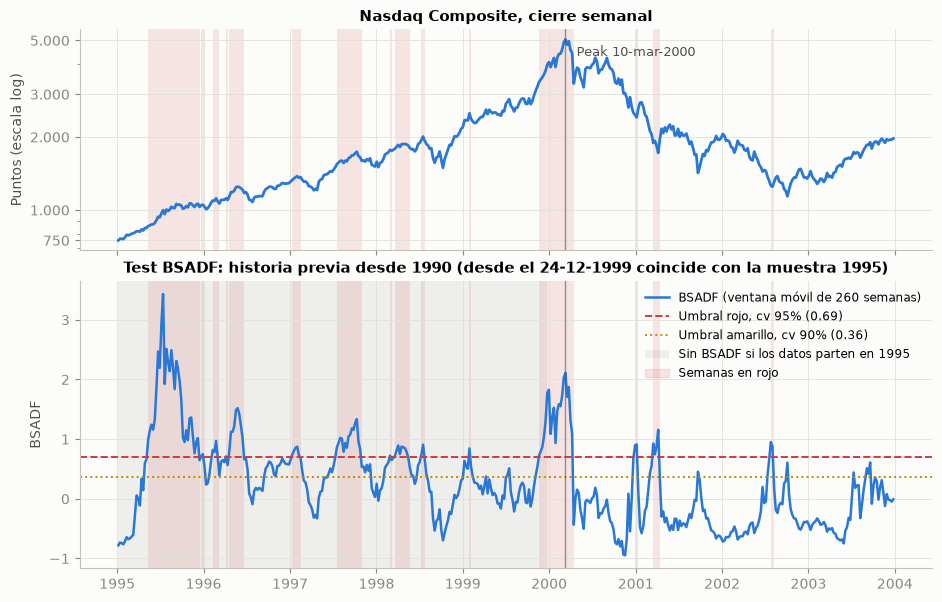

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.3], "hspace": 0.12})
s90 = semanal_90.loc["1995":"2003"]
ax1.plot(s90.index, s90, color=AZUL, lw=2)
ax1.set_yscale("log")
ax1.set_yticks([750, 1000, 2000, 3000, 5000])
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_ylabel("Puntos (escala log)")
ax1.set_title("Nasdaq Composite, cierre semanal")

ax2.plot(ventana_90.index, ventana_90, color=AZUL, lw=1.8, label="BSADF (ventana móvil de 260 semanas)")
ax2.axhline(ROJO, color=COLOR_SEMAFORO["rojo"], lw=1.4, ls="--", label=f"Umbral rojo, cv 95% ({ROJO:.2f})")
ax2.axhline(AMARILLO, color="#c98500", lw=1.4, ls=":", label=f"Umbral amarillo, cv 90% ({AMARILLO:.2f})")
ax2.axvspan(ventana_90.index[0], primera_semana, color=GRIS, alpha=0.08, lw=0,
            label="Sin BSADF si los datos parten en 1995")
ax2.set_ylabel("BSADF")
ax2.set_title("Test BSADF: historia previa desde 1990 (desde el 24-12-1999 coincide con la muestra 1995)")
for ax in (ax1, ax2):
    for _, ep in ep_rojo_90.iterrows():
        ax.axvspan(ep["inicio"], ep["fin"] + pd.Timedelta(days=7), color=COLOR_SEMAFORO["rojo"], alpha=0.12, lw=0)
    ax.axvline(PEAK, color=GRIS, lw=1, alpha=0.6)
ax1.annotate("Peak 10-mar-2000", xy=(PEAK, s90.max()), xytext=(8, -4), textcoords="offset points",
             color=GRIS, fontsize=9, va="top")
ax2.fill_between([], [], color=COLOR_SEMAFORO["rojo"], alpha=0.12, label="Semanas en rojo")
ax2.legend(loc="upper right", frameon=False, fontsize=8.5)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

**Cómo leerlo:**
- El episodio que precede al peak empieza en noviembre de 1999 y se apaga en abril de 2000, cuando el precio deja de acelerar. Es la misma fecha que encontró el notebook 01.
- **Pero el rojo también se enciende varias veces entre 1995 y 1998.** El Nasdaq tuvo tramos de crecimiento muy rápido en esos años (por ejemplo, 1995) que el test, con solo 5 años de memoria, califica como explosivos. Para el BSADF eso no es un error: son tramos explosivos *localmente*. Pero en el backtest se traducirán en reducciones de exposición años antes del peak, con su costo de oportunidad.

### 4.3 Comparación con el notebook 01

In [7]:
cv_01, cv_sec_01 = S.valores_criticos_mc(len(lp_95), S.ventana_minima(len(lp_95))[1], n_sim=2000, semilla=42)
seq_01 = S.secuencia_adf(lp_95, S.ventana_minima(len(lp_95))[1])
amarilla_01 = S.primera_senal(seq_01, cv_sec_01[1])
roja_01 = S.primera_senal(seq_01, cv_01[0.95])

semanas = lambda f: (PEAK - f).days // 7
comparacion = pd.DataFrame([
    {"método": "SADF anclado (notebook 01), datos desde 1995",
     "primera alerta": amarilla_01.date(), "semanas antes (alerta)": semanas(amarilla_01),
     "primer rojo": roja_01.date(), "semanas antes (rojo)": semanas(roja_01)},
    {"método": "BSADF móvil, datos desde 1995 (señal censurada)",
     "primera alerta": primera_amarilla_95.date(), "semanas antes (alerta)": semanas(primera_amarilla_95),
     "primer rojo": primera_roja_95.date(), "semanas antes (rojo)": semanas(primera_roja_95)},
    {"método": "BSADF móvil, historia desde 1990 (episodio vigente en el peak)",
     "primera alerta": inicio_alerta_peak.date(), "semanas antes (alerta)": semanas(inicio_alerta_peak),
     "primer rojo": inicio_rojo_peak.date(), "semanas antes (rojo)": semanas(inicio_rojo_peak)},
]).set_index("método")
comparacion

,primera alerta,semanas antes (alerta),primer rojo,semanas antes (rojo)
método,,,,
"SADF anclado (notebook 01), datos desde 1995",1999-11-12,17,2000-03-03,1
"BSADF móvil, datos desde 1995 (señal censurada)",1999-12-24,11,1999-12-24,11
"BSADF móvil, historia desde 1990 (episodio vigente en el peak)",1999-11-05,18,1999-11-19,16


**Cómo leerlo:** con historia suficiente, el BSADF enciende **rojo** ~16 semanas antes del peak, donde el SADF anclado solo encendía **amarillo** y su rojo llegaba una semana antes. **La puntocom se sigue detectando antes del peak, y ahora con la señal fuerte.** Con datos desde 1995 la señal existe pero está censurada.

**Implicancia para el backtest:** para evaluar la puntocom con el BSADF, ^IXIC necesita historia desde 1990. `FECHA_INICIO = 1995` en `config.py`, así que el backtest descarga aparte la historia de ^IXIC desde 1990.

## 5. Semáforo del universo con BSADF (señal bruta, sin persistencia)

`F.construir_panel` entrega dos columnas: `semaforo_bruto` (el umbral aplicado semana a semana) y `semaforo` (con la persistencia de 6 semanas de la sección 8). Las secciones 5 a 7 analizan la **señal bruta**, para entender su comportamiento antes de filtrarla.

In [8]:
validados = pd.read_csv(C.DIR_PROCESSED / "precios_validados.csv", parse_dates=["fecha"])
inicio = time.time()
panel = F.construir_panel(validados)                          # metodología vigente: BSADF
print(f"Panel BSADF en {time.time() - inicio:.0f} s")
inicio = time.time()
panel_anclado = F.construir_panel(validados, metodo="anclado")  # referencia (notebook 03)
print(f"Panel anclado (comparación) en {time.time() - inicio:.0f} s")
orden = list(C.UNIVERSO) + list(C.INDICES)

INFO     radar.features | Umbrales BSADF (260 semanas): amarillo 0.360, rojo 0.694; persistencia 6 semanas


INFO     radar.features | AMD: 1402 semanas con BSADF, semáforo actual amarillo (bruto verde)


INFO     radar.features | AMZN: 1279 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | AVGO: 641 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | GOOGL: 900 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | META: 496 semanas con BSADF, semáforo actual verde (bruto verde)


... (15 outputs left out)

INFO     radar.features | TSM: T = 1517 semanas, n0 = 85, semáforo actual amarillo


INFO     radar.features | ^GSPC: T = 1661 semanas, n0 = 89, semáforo actual verde


INFO     radar.features | ^IXIC: T = 1661 semanas, n0 = 89, semáforo actual verde


Panel anclado (comparación) en 39 s


### 5.1 Historia del semáforo (señal bruta)

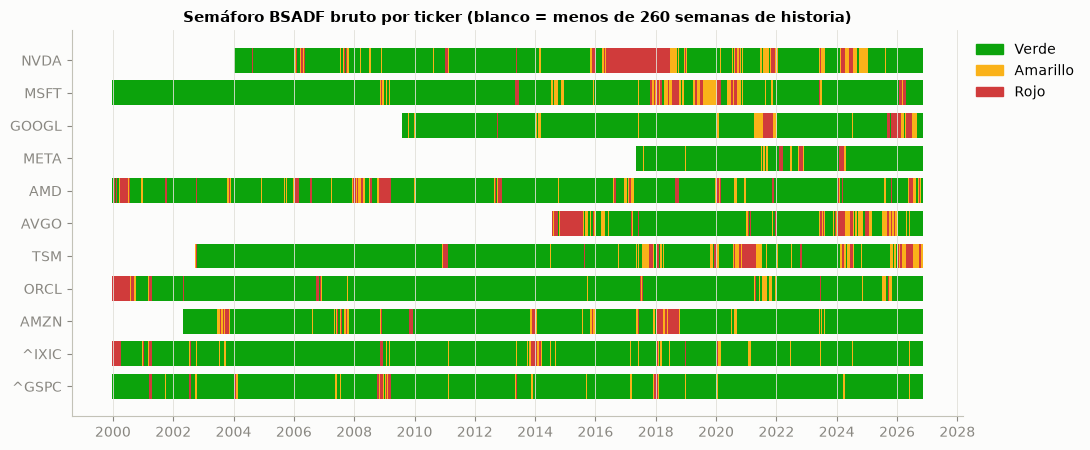

In [9]:
def franjas(p, columna, titulo):
    # Gráfico de franjas: una fila por ticker, color del semáforo semana a semana
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for i, t in enumerate(orden):
        g = p[p["ticker"] == t].dropna(subset=[columna])
        tramo = (g[columna] != g[columna].shift()).cumsum()
        for _, seg in g.groupby(tramo):
            ini, fin = seg["fecha"].iloc[0], seg["fecha"].iloc[-1] + pd.Timedelta(days=7)
            ax.broken_barh([(mdates.date2num(ini), (fin - ini).days)], (i - 0.38, 0.76),
                           color=COLOR_SEMAFORO[seg[columna].iloc[0]], lw=0)
    ax.set_yticks(range(len(orden)), orden)
    ax.invert_yaxis()
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
    ax.legend(handles=[Patch(color=v, label=k.capitalize()) for k, v in COLOR_SEMAFORO.items()],
              loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    plt.tight_layout()
    plt.show()

franjas(panel, "semaforo_bruto", "Semáforo BSADF bruto por ticker (blanco = menos de 260 semanas de historia)")

**Cómo leerlo:** frente al gráfico del notebook 03 aparece mucho más rojo, concentrado en ciclos de alza: 2000 en ^IXIC y ORCL; 2014-2018 en AVGO, NVDA y AMZN; 2017-2021 en MSFT; 2021 y 2023-2026 en TSM, GOOGL, META y otras. Las series con historia desde 1995 tienen semáforo recién desde 2000, cuando completan 260 semanas. Las franjas rojas suelen ser cortas y en algunos casos alternan con verde de una semana a otra: esa es la inestabilidad que la regla de persistencia (sección 7) intenta reducir.

### 5.2 Diagnóstico: BSADF vs. SADF anclado

In [10]:
def diagnostico(p, estadistico, columna="semaforo"):
    filas = []
    for t in orden:
        g = p[p["ticker"] == t].dropna(subset=[columna]).set_index("fecha")
        no_verde, rojo = tramos(g[columna] != "verde"), tramos(g[columna] == "rojo")
        reciente = g.loc["2023":, estadistico]
        filas.append({
            "ticker": t, "semanas": len(g),
            "% amarillo": (g[columna] == "amarillo").mean(), "% rojo": (g[columna] == "rojo").mean(),
            "episodios no verdes": len(no_verde), "de 1-2 semanas": int((no_verde["semanas"] <= 2).sum()),
            "episodios rojos": len(rojo), "rojos de 1-2 semanas": int((rojo["semanas"] <= 2).sum()),
            "máx. desde 2023": reciente.max(), "fecha máx.": reciente.idxmax().date(),
        })
    return pd.DataFrame(filas).set_index("ticker")

diag = diagnostico(panel, "bsadf", "semaforo_bruto")
diag_anclado = diagnostico(panel_anclado, "adf")
diag["umbral rojo"] = ROJO
diag["¿rojo desde 2023?"] = np.where(diag["máx. desde 2023"] > ROJO, "Sí", "No")
diag["% rojo (anclado)"] = diag_anclado["% rojo"]
diag["% amarillo (anclado)"] = diag_anclado["% amarillo"]
(diag.style.format({c: "{:.1%}" for c in ["% amarillo", "% rojo", "% rojo (anclado)", "% amarillo (anclado)"]}
                   | {"máx. desde 2023": "{:.2f}", "umbral rojo": "{:.2f}"}))

,semanas,% amarillo,% rojo,episodios no verdes,de 1-2 semanas,episodios rojos,rojos de 1-2 semanas,máx. desde 2023,fecha máx.,umbral rojo,¿rojo desde 2023?,% rojo (anclado),% amarillo (anclado)
ticker,,,,,,,,,,,,,
NVDA,1191,10.9%,14.2%,40,23,25,17,1.31,2024-03-22,0.69,Sí,0.0%,11.8%
MSFT,1402,8.4%,5.1%,28,16,22,11,2.44,2026-02-06,0.69,Sí,0.0%,2.9%
GOOGL,900,6.3%,5.8%,17,10,10,5,1.91,2025-09-19,0.69,Sí,0.0%,0.0%
META,496,5.6%,4.0%,16,11,5,2,2.10,2024-02-02,0.69,Sí,0.0%,0.0%
AMD,1402,6.6%,8.5%,42,16,34,23,1.20,2026-05-29,0.69,Sí,0.0%,1.7%
AVGO,641,15.4%,15.3%,27,8,23,13,1.20,2024-03-01,0.69,Sí,0.0%,25.9%
TSM,1258,8.9%,7.5%,30,14,22,10,1.49,2024-03-08,0.69,Sí,0.0%,16.1%
ORCL,1402,3.4%,4.4%,27,17,14,10,1.61,2023-06-16,0.69,Sí,0.3%,2.9%
AMZN,1279,5.8%,5.2%,30,19,20,13,0.51,2023-07-14,0.69,No,0.0%,0.3%


In [11]:
total = lambda d, col: (d[col] * d["semanas"]).sum() / d["semanas"].sum()
print(f"Universo completo — % de semanas en rojo:     BSADF {total(diag, '% rojo'):.1%} | anclado {total(diag_anclado, '% rojo'):.1%}")
print(f"Universo completo — % de semanas en amarillo: BSADF {total(diag, '% amarillo'):.1%} | anclado {total(diag_anclado, '% amarillo'):.1%}")
print(f"Episodios rojos: {diag['episodios rojos'].sum()}, de ellos de 1-2 semanas: {diag['rojos de 1-2 semanas'].sum()} "
      f"({diag['rojos de 1-2 semanas'].sum() / diag['episodios rojos'].sum():.0%})")
print(f"Acciones/índices que llegan a rojo desde 2023: {(diag['¿rojo desde 2023?'] == 'Sí').sum()} de {len(diag)}")

Universo completo — % de semanas en rojo:     BSADF 6.6% | anclado 0.0%
Universo completo — % de semanas en amarillo: BSADF 6.8% | anclado 5.1%
Episodios rojos: 204, de ellos de 1-2 semanas: 118 (58%)
Acciones/índices que llegan a rojo desde 2023: 8 de 11


**Cómo leerlo:**
- **El ciclo reciente de IA sí llega a rojo:** desde 2023, el BSADF máximo supera el umbral rojo en **8 de las 9 acciones** (todas salvo AMZN). Los índices no llegan a rojo en ese período. Con el método anclado, ninguna serie lo lograba.
- **El rojo no domina:** en el agregado está alrededor del 7% de las semanas. Hay heterogeneidad: las acciones de mayor crecimiento (NVDA, AVGO) pasan más tiempo en rojo.
- **El costo es la inestabilidad:** más de la mitad de los episodios rojos (58%) dura 1-2 semanas. Para un comité que se reúne semanalmente, un rojo que aparece y desaparece a la semana siguiente es difícil de accionar.

## 6. Tasa de falsas alarmas

Se simulan series **sin burbuja** (caminatas aleatorias) del mismo largo que la historia más larga del universo (1.661 semanas), se les aplica exactamente el mismo BSADF móvil y se cuenta cuántas veces se enciende el rojo. Se usan 500 simulaciones (cada una requiere ~1.400 semanas × 230 regresiones).

In [12]:
NIVEL = {"verde": 0, "amarillo": 1, "rojo": 2}
COLOR = {v: k for k, v in NIVEL.items()}

def persistencia(niveles, semanas=2):
    # Cambia de color solo si las últimas `semanas` están todas sobre (o todas bajo) el nivel actual
    niveles = np.asarray(niveles)
    estado, salida = niveles[0], np.empty_like(niveles)
    for i in range(len(niveles)):
        if i >= semanas - 1:
            ultimas = niveles[i - semanas + 1: i + 1]
            if ultimas.min() > estado:
                estado = ultimas.min()
            elif ultimas.max() < estado:
                estado = ultimas.max()
        salida[i] = estado
    return salida

T_LARGO, N_SIM_FA = 1661, 500
rng = np.random.default_rng(2026)
resultados = []
inicio = time.time()
for _ in range(N_SIM_FA):
    y = np.cumsum(1.0 / T_LARGO + rng.standard_normal(T_LARGO))
    bs = S.adf_hacia_atras(np.lib.stride_tricks.sliding_window_view(y, W), N0).max(axis=-1)
    nivel = np.select([bs > ROJO, bs > AMARILLO], [2, 1], 0)
    nivel_6 = np.array([F.NIVEL[c] for c in F.aplicar_persistencia(np.array(["verde", "amarillo", "rojo"])[nivel], 6)])
    for regla, niv in (("sin persistencia", nivel), ("persistencia 2 semanas", persistencia(nivel)),
                       ("persistencia 6 semanas", nivel_6)):
        rojo = tramos(niv == 2)
        resultados.append({"regla": regla, "alguna vez rojo": (niv == 2).any(), "% semanas rojo": (niv == 2).mean(),
                           "% semanas amarillo": (niv == 1).mean(), "episodios rojos": len(rojo),
                           "rojos de 1-2 semanas": int((rojo["semanas"] <= 2).sum())})
print(f"{N_SIM_FA} series sin burbuja simuladas en {time.time() - inicio:.0f} s")

falsas = pd.DataFrame(resultados).groupby("regla", sort=False).mean()
falsas["semanas por serie"] = T_LARGO - W + 1
falsas.style.format({"alguna vez rojo": "{:.1%}", "% semanas rojo": "{:.1%}", "% semanas amarillo": "{:.1%}",
                     "episodios rojos": "{:.1f}", "rojos de 1-2 semanas": "{:.1f}"})

500 series sin burbuja simuladas en 213 s


,alguna vez rojo,% semanas rojo,% semanas amarillo,episodios rojos,rojos de 1-2 semanas,semanas por serie
regla,,,,,,
sin persistencia,100.0%,4.9%,4.8%,16.9,10.0,1402
persistencia 2 semanas,100.0%,4.6%,4.7%,9.0,2.6,1402
persistencia 6 semanas,93.2%,3.3%,4.1%,2.7,0.0,1402


**Cómo leerlo (fila "sin persistencia"):**
- **% de semanas en rojo ≈ 5%**: es exactamente lo que promete un umbral del 95%. Cada semana, por separado, tiene un 5% de probabilidad de falsa alarma.
- **Prácticamente el 100% de las series sin burbuja se enciende en rojo al menos una vez** en ~1.400 semanas. Es inevitable con un test semana a semana: con 1.400 oportunidades, alguna supera el umbral por azar. El SADF anclado tenía el mismo problema en amarillo (~66%, notebook 01).
- La pregunta útil para el comité no es *"¿se enciende alguna vez?"* sino *"¿cuántos episodios falsos esperar y cuánto duran?"*: ~17 episodios rojos falsos en ~27 años de semanas evaluadas (uno cada ~1,6 años por serie), de los cuales ~10 duran 1-2 semanas.

**Comparación con el universo real:** el universo pasa ~7% de las semanas en rojo frente al ~5% esperado sin burbujas, y lo concentra en los ciclos de alza. Hay señal real, pero también una parte de ruido que el comité debe saber leer.

## 7. Alternativa evaluada: persistencia de 2 semanas

> Alternativa menos exigente. **El semáforo vigente usa 6 semanas** (sección 8); esta sección se conserva para comparar.

**Regla evaluada:** el semáforo cambia de color solo si el BSADF se mantiene **2 semanas seguidas** del otro lado del umbral:
- Para subir (verde → amarillo → rojo): las 2 últimas semanas sobre el umbral del nuevo color.
- Para bajar: las 2 últimas semanas bajo el umbral del color actual.

Es una regla simétrica con *histéresis*: evita que una semana aislada cambie el color, en ambos sentidos. Una versión ingenua ("2 semanas del mismo color") dejaría en verde a una acción que alterna amarillo-rojo-amarillo, algo claramente no deseado. El costo es **una semana de retraso** al entrar y al salir.

### 7.1 Efecto en el universo

In [13]:
def con_persistencia(p):
    p = p.dropna(subset=["semaforo_bruto"]).copy()
    p["semaforo_p2"] = p.groupby("ticker")["semaforo_bruto"].transform(
        lambda s: [COLOR[n] for n in persistencia(s.map(NIVEL).to_numpy())])
    return p

diag_p = diagnostico(con_persistencia(panel), "bsadf", "semaforo_p2")
efecto = pd.DataFrame({
    "episodios rojos (sin)": diag["episodios rojos"], "episodios rojos (con)": diag_p["episodios rojos"],
    "rojos 1-2 sem. (sin)": diag["rojos de 1-2 semanas"], "rojos 1-2 sem. (con)": diag_p["rojos de 1-2 semanas"],
    "episodios no verdes (sin)": diag["episodios no verdes"], "episodios no verdes (con)": diag_p["episodios no verdes"],
    "% rojo (sin)": diag["% rojo"], "% rojo (con)": diag_p["% rojo"],
})
efecto.loc["TOTAL"] = efecto.sum()
efecto.loc["TOTAL", ["% rojo (sin)", "% rojo (con)"]] = [total(diag, "% rojo"), total(diag_p, "% rojo")]
print("(sin) = semáforo actual; (con) = con persistencia de 2 semanas")
efecto.style.format({"% rojo (sin)": "{:.1%}", "% rojo (con)": "{:.1%}"}, precision=0)

(sin) = semáforo actual; (con) = con persistencia de 2 semanas


,episodios rojos (sin),episodios rojos (con),rojos 1-2 sem. (sin),rojos 1-2 sem. (con),episodios no verdes (sin),episodios no verdes (con),% rojo (sin),% rojo (con)
ticker,,,,,,,,
NVDA,25,10,17,2,40,18,14.2%,13.3%
MSFT,22,13,11,3,28,14,5.1%,4.6%
GOOGL,10,5,5,1,17,8,5.8%,5.7%
META,5,3,2,0,16,5,4.0%,4.4%
AMD,34,22,23,10,42,28,8.5%,7.8%
AVGO,23,14,13,5,27,16,15.3%,14.4%
TSM,22,12,10,1,30,15,7.5%,7.0%
ORCL,14,8,10,4,27,14,4.4%,4.3%
AMZN,20,8,13,1,30,16,5.2%,4.7%


### 7.2 Efecto en la anticipación de la puntocom (historia desde 1990)

In [14]:
nivel_90 = pd.Series(np.select([ventana_90 > ROJO, ventana_90 > AMARILLO], [2, 1], 0), index=ventana_90.index)
nivel_90_p = pd.Series(persistencia(nivel_90.to_numpy()), index=ventana_90.index)

filas = []
for regla, niv in (("sin persistencia", nivel_90), ("persistencia 2 semanas", nivel_90_p)):
    ini_rojo = inicio_episodio_en(niv == 2, PEAK)
    ini_alerta = inicio_episodio_en(niv >= 1, PEAK)
    filas.append({"regla": regla,
                  "alerta desde": ini_alerta.date(), "semanas antes (alerta)": semanas(ini_alerta),
                  "rojo desde": ini_rojo.date(), "semanas antes (rojo)": semanas(ini_rojo),
                  "episodios rojos 1995 - peak": int((tramos(niv.loc[:PEAK] == 2)["inicio"] >= "1995").sum())})
pd.DataFrame(filas).set_index("regla")

,alerta desde,semanas antes (alerta),rojo desde,semanas antes (rojo),episodios rojos 1995 - peak
regla,,,,,
sin persistencia,1999-11-05,18,1999-11-19,16,12
persistencia 2 semanas,1999-11-12,17,1999-11-26,15,8


### 7.3 Ventajas de la persistencia

Una persistencia corta ya mejora el semáforo, por tres razones:
1. **Elimina la mayoría de los episodios rojos de 1-2 semanas**, tanto en el universo real como en las series sin burbuja (secciones 6 y 7.1). El comité recibe menos cambios de color sin contenido.
2. **El costo en anticipación es de una semana**: la puntocom sigue detectándose con varios meses de anticipación (7.2).
3. **Coincide con el uso del producto:** una reunión semanal que decide reducir o cubrir exposición necesita señales que se sostengan al menos hasta la reunión siguiente.

Lo que la persistencia **no** resuelve: los episodios rojos de 1995-1998 en el Nasdaq son largos y la regla no los elimina. Son tramos explosivos reales a 5 años vista; su costo se medirá en el backtest.

**Se adopta una persistencia de 6 semanas**, más exigente y anclada en la literatura (sección 8).

## 8. Decisión: persistencia de 6 semanas (duración mínima de PSY 2015)

Phillips, Shi y Yu (2015) proponen que un episodio solo cuente como burbuja si dura al menos $\log(T)$ períodos. Con la ventana de $T = 260$ semanas, $\log(260) \approx 5{,}6$, que se redondea a **6 semanas**.

**Regla aplicada** (`F.aplicar_persistencia`, integrada en `src/features.py`): el semáforo cambia de color solo después de **6 semanas seguidas** en el nuevo nivel, en ambas direcciones:
- **Para subir:** las últimas 6 semanas sobre el umbral del nuevo color (pasa al menor nivel de esas 6).
- **Para bajar:** las últimas 6 semanas bajo el nivel actual (pasa al mayor nivel de esas 6).
- Cada serie parte en verde: no hay rojo sin 6 semanas de evidencia.

La señal sin filtro se conserva en `semaforo_bruto`, para que el reporte pueda explicar, por ejemplo, que una acción sigue en rojo aunque esta semana su BSADF ya esté bajo el umbral.

### 8.1 Efecto en el universo: señal bruta vs. 2 semanas vs. 6 semanas

In [15]:
diag_6 = diagnostico(panel, "bsadf", "semaforo")
comparacion_persistencia = pd.DataFrame({
    "episodios rojos": [diag["episodios rojos"].sum(), diag_p["episodios rojos"].sum(), diag_6["episodios rojos"].sum()],
    "rojos de 1-2 semanas": [diag["rojos de 1-2 semanas"].sum(), diag_p["rojos de 1-2 semanas"].sum(),
                             diag_6["rojos de 1-2 semanas"].sum()],
    "episodios no verdes": [diag["episodios no verdes"].sum(), diag_p["episodios no verdes"].sum(),
                            diag_6["episodios no verdes"].sum()],
    "% semanas en rojo": [total(diag, "% rojo"), total(diag_p, "% rojo"), total(diag_6, "% rojo")],
    "% semanas en amarillo": [total(diag, "% amarillo"), total(diag_p, "% amarillo"), total(diag_6, "% amarillo")],
}, index=["Señal bruta", "Persistencia 2 semanas", "Persistencia 6 semanas (vigente)"])
comparacion_persistencia.style.format({"% semanas en rojo": "{:.1%}", "% semanas en amarillo": "{:.1%}"})

,episodios rojos,rojos de 1-2 semanas,episodios no verdes,% semanas en rojo,% semanas en amarillo
Señal bruta,204,118,331,6.6%,6.8%
Persistencia 2 semanas,111,31,167,6.2%,6.8%
Persistencia 6 semanas (vigente),32,0,61,4.3%,6.4%


In [16]:
print("Por ticker, con persistencia de 6 semanas:")
diag_6[["semanas", "% amarillo", "% rojo", "episodios no verdes", "episodios rojos", "rojos de 1-2 semanas",
        "máx. desde 2023"]].style.format({"% amarillo": "{:.1%}", "% rojo": "{:.1%}", "máx. desde 2023": "{:.2f}"})

Por ticker, con persistencia de 6 semanas:


,semanas,% amarillo,% rojo,episodios no verdes,episodios rojos,rojos de 1-2 semanas,máx. desde 2023
ticker,,,,,,,
NVDA,1191,10.6%,11.8%,8,5,0,1.31
MSFT,1402,11.5%,1.4%,6,2,0,2.44
GOOGL,900,5.2%,4.9%,3,3,0,1.91
META,496,2.8%,4.4%,3,3,0,2.10
AMD,1402,6.3%,4.9%,11,6,0,1.20
AVGO,641,17.5%,10.8%,5,3,0,1.20
TSM,1258,8.5%,5.6%,6,5,0,1.49
ORCL,1402,2.4%,2.7%,5,1,0,1.61
AMZN,1279,4.5%,3.6%,7,2,0,0.51


**Cómo leerlo:** con 6 semanas **desaparecen los episodios rojos de 1-2 semanas**: la regla, por construcción, no permite un rojo más corto que 6 semanas. Los episodios rojos caen a una fracción de los de la señal bruta. El % de semanas en rojo baja menos, porque los episodios largos se mantienen. El semáforo pasa de "parpadear" a marcar pocos períodos bien definidos.

### 8.2 Puntocom y falsas alarmas con 6 semanas

In [17]:
colores_90_6 = pd.Series(F.aplicar_persistencia(F.semaforo(ventana_90, AMARILLO, ROJO), 6), index=ventana_90.index)
anticipacion_6 = B.anticipacion_rojo(colores_90_6, PEAK)
inicio_rojo_6 = PEAK - pd.Timedelta(weeks=anticipacion_6)
print(f"^IXIC (historia desde 1990), persistencia 6 semanas: rojo desde {inicio_rojo_6:%d-%m-%Y}, "
      f"{anticipacion_6} semanas antes del peak (señal bruta: {semanas(inicio_rojo_peak)} semanas)")
print(f"Episodios rojos entre 1995 y el peak: {len(tramos(colores_90_6.loc['1995':PEAK] == 'rojo'))} "
      f"(señal bruta: {(ep_rojo_90['inicio'] < PEAK).sum()})")
print("\nSeries sin burbuja (sección 6):")
falsas.style.format({"alguna vez rojo": "{:.1%}", "% semanas rojo": "{:.1%}", "% semanas amarillo": "{:.1%}",
                     "episodios rojos": "{:.1f}", "rojos de 1-2 semanas": "{:.1f}"})

^IXIC (historia desde 1990), persistencia 6 semanas: rojo desde 24-12-1999, 11 semanas antes del peak (señal bruta: 16 semanas)
Episodios rojos entre 1995 y el peak: 4 (señal bruta: 12)

Series sin burbuja (sección 6):


,alguna vez rojo,% semanas rojo,% semanas amarillo,episodios rojos,rojos de 1-2 semanas,semanas por serie
regla,,,,,,
sin persistencia,100.0%,4.9%,4.8%,16.9,10.0,1402
persistencia 2 semanas,100.0%,4.6%,4.7%,9.0,2.6,1402
persistencia 6 semanas,93.2%,3.3%,4.1%,2.7,0.0,1402


**Cómo leerlo:**
- **Puntocom:** la persistencia retrasa el rojo exactamente lo que exige (de 16 a 11 semanas antes del peak). Sigue siendo una alerta con casi 3 meses de anticipación.
- **Falsas alarmas:** en series sin burbuja, los episodios rojos caen de ~17 a menos de 3 por serie (en ~27 años de semanas evaluadas) y desaparecen los de 1-2 semanas. Sigue siendo muy probable que una serie larga tenga *algún* rojo falso: es el precio de evaluar más de 1.400 semanas. Por eso el reporte acompaña el color con su duración y las variables de contexto.

### 8.3 Semáforo vigente

In [18]:
actual = F.semaforo_actual(panel)
actual["nombre"] = actual["ticker"].map({**C.UNIVERSO, **C.INDICES})
print(f"Semana del {actual['fecha'].max():%d-%m-%Y} — BSADF {W} semanas, persistencia {C.PERSISTENCIA_SEMANAS} semanas")
(actual[["ticker", "nombre", "semaforo", "semanas_en_estado", "semaforo_bruto", "bsadf", "cv_bsadf_90", "cv_bsadf_95",
         "momentum_52s", "volatilidad_anual", "beta_104s"]].set_index("ticker").style
 .format({"bsadf": "{:.2f}", "cv_bsadf_90": "{:.2f}", "cv_bsadf_95": "{:.2f}", "momentum_52s": "{:+.1%}",
          "volatilidad_anual": "{:.1%}", "beta_104s": "{:.2f}"})
 .map(lambda v: f"background-color: {COLOR_SEMAFORO[v]}; color: {'#0b0b0b' if v == 'amarillo' else 'white'}; "
                "font-weight: bold", subset=["semaforo"]))

Semana del 30-10-2026 — BSADF 260 semanas, persistencia 6 semanas


,nombre,semaforo,semanas_en_estado,semaforo_bruto,bsadf,cv_bsadf_90,cv_bsadf_95,momentum_52s,volatilidad_anual,beta_104s
ticker,,,,,,,,,,
TSM,Taiwan Semiconductor,rojo,23,amarillo,0.40,0.36,0.69,+36.6%,29.9%,1.45
AMD,Advanced Micro Devices,amarillo,11,verde,0.01,0.36,0.69,+97.1%,63.4%,1.89
^GSPC,S&P 500,verde,451,verde,0.09,0.36,0.69,+10.8%,11.9%,1.00
^IXIC,Nasdaq Composite,verde,653,verde,-0.06,0.36,0.69,+7.2%,18.3%,1.29
NVDA,NVIDIA,verde,87,verde,-0.21,0.36,0.69,+1.3%,32.0%,1.85
GOOGL,Alphabet,verde,4,verde,-0.29,0.36,0.69,-0.2%,35.4%,1.24
AVGO,Broadcom,verde,38,verde,-0.46,0.36,0.69,-11.1%,45.0%,2.24
META,Meta Platforms,verde,128,verde,-0.67,0.36,0.69,-4.8%,43.0%,1.65
MSFT,Microsoft,verde,24,verde,-0.69,0.36,0.69,+1.6%,35.9%,1.10


**Cómo leer la tabla:** `semaforo` es el color que ve el comité (con persistencia) y `semaforo_bruto` es la señal de esta semana. Cuando difieren, el color está "en transición": por ejemplo, TSM sigue en rojo aunque esta semana su BSADF esté en zona amarilla. Bajará solo si se mantiene 6 semanas bajo el umbral rojo.

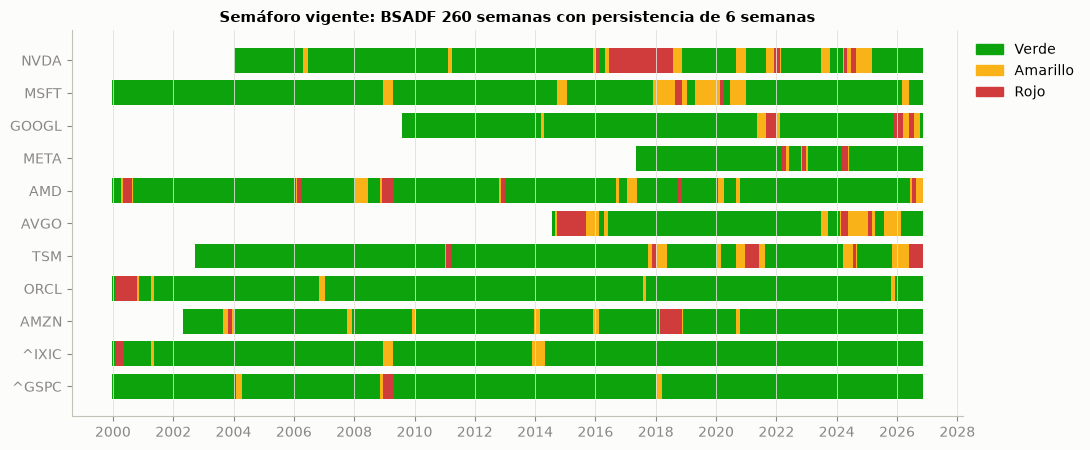

In [19]:
franjas(panel, "semaforo", "Semáforo vigente: BSADF 260 semanas con persistencia de 6 semanas")

### 8.4 Guardado

Se guardan el panel semanal y el semáforo actual con BSADF y persistencia en `data/processed/`. Los valores críticos del Monte Carlo quedan en `data/processed/cv_bsadf.json` y se reutilizan en cada ejecución. Solo se vuelven a simular si cambian la ventana, los rezagos, la semilla o el número de simulaciones.

In [20]:
F.guardar(panel, actual.drop(columns="nombre"))
import json
print(json.dumps(json.loads(C.RUTA_CV_BSADF.read_text(encoding="utf-8"))[f"ventana={W}"], indent=2, ensure_ascii=False))

INFO     radar.features | Panel semanal y semáforo actual guardados en data/processed


{
  "parametros": {
    "ventana": 260,
    "rezagos": 1,
    "semilla": 42,
    "n_sim": 20000
  },
  "valores_criticos": {
    "0.9": 0.35987635352985636,
    "0.95": 0.6943720334004567,
    "0.99": 1.3708999643712374
  },
  "fecha_calculo": "2026-11-01 20:05:49"
}


## 9. Sensibilidad: ventanas de 156, 260 y 364 semanas

La ventana vigente sigue siendo **260 semanas**. Esta sección solo verifica que las conclusiones no dependan de esa elección. Se repite todo con ventanas de 3, 5 y 7 años, siempre con persistencia de 6 semanas. Las falsas alarmas se miden con 200 series sin burbuja por ventana, menos que las 500 de la sección 6, para acotar el tiempo de cálculo.

In [21]:
VENTANAS = (156, 260, 364)
N_SIM_SENS = 200
resumen_sens, pct_rojo_sens, actual_sens = [], {}, {}
inicio = time.time()
for w in VENTANAS:
    cv_w = F.valores_criticos_cache(w)
    am_w, ro_w = cv_w[C.CUANTIL_AMARILLO], cv_w[C.CUANTIL_ROJO]
    _, n0_w = S.ventana_minima(w)

    # Puntocom (^IXIC con historia desde 1990)
    bs_w = S.bsadf_movil(np.log(semanal_90), w)
    col_w = pd.Series(F.aplicar_persistencia(F.semaforo(bs_w, am_w, ro_w)), index=bs_w.index)
    ant_w = B.anticipacion_rojo(col_w, PEAK)

    # Universo
    panel_w = F.construir_panel(validados, ventana=w)
    pct_rojo_sens[w] = panel_w.dropna(subset=["semaforo"]).groupby("ticker")["semaforo"].apply(lambda s: (s == "rojo").mean())
    actual_sens[w] = F.semaforo_actual(panel_w).set_index("ticker")["semaforo"]

    # Falsas alarmas
    rng = np.random.default_rng(2026)
    fa = []
    for _ in range(N_SIM_SENS):
        y = np.cumsum(1.0 / T_LARGO + rng.standard_normal(T_LARGO))
        b = S.adf_hacia_atras(np.lib.stride_tricks.sliding_window_view(y, w), n0_w).max(axis=-1)
        c = F.aplicar_persistencia(F.semaforo(b, am_w, ro_w))
        fa.append({"alguna vez rojo": (c == "rojo").any(), "% semanas rojo": (c == "rojo").mean(),
                   "episodios rojos": len(tramos(c == "rojo"))})
    fa = pd.DataFrame(fa).mean()

    resumen_sens.append({
        "ventana (semanas)": w, "n0": n0_w, "cv 90%": am_w, "cv 95%": ro_w,
        "^IXIC: primera semana con señal": bs_w.index[0].date(),
        "rojo antes del peak 2000 (semanas)": ant_w if ant_w is not None else "sin señal",
        "universo: % semanas en rojo": (panel_w["semaforo"] == "rojo").sum() / panel_w["semaforo"].notna().sum(),
        "sin burbuja: alguna vez rojo": fa["alguna vez rojo"], "sin burbuja: % semanas rojo": fa["% semanas rojo"],
        "sin burbuja: episodios rojos por serie": fa["episodios rojos"],
    })
print(f"Sensibilidad calculada en {time.time() - inicio:.0f} s")
pd.DataFrame(resumen_sens).set_index("ventana (semanas)").style.format(
    {"cv 90%": "{:.3f}", "cv 95%": "{:.3f}", "universo: % semanas en rojo": "{:.1%}",
     "sin burbuja: alguna vez rojo": "{:.1%}", "sin burbuja: % semanas rojo": "{:.1%}",
     "sin burbuja: episodios rojos por serie": "{:.1f}"})

INFO     radar.features | Umbrales BSADF (156 semanas): amarillo 0.352, rojo 0.719; persistencia 6 semanas


INFO     radar.features | AMD: 1506 semanas con BSADF, semáforo actual amarillo (bruto verde)


INFO     radar.features | AMZN: 1383 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | AVGO: 745 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | GOOGL: 1004 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | META: 600 semanas con BSADF, semáforo actual verde (bruto verde)


... (28 outputs left out)

INFO     radar.features | ^GSPC: 1298 semanas con BSADF, semáforo actual verde (bruto verde)


INFO     radar.features | ^IXIC: 1298 semanas con BSADF, semáforo actual verde (bruto verde)


Sensibilidad calculada en 265 s


,n0,cv 90%,cv 95%,^IXIC: primera semana con señal,rojo antes del peak 2000 (semanas),universo: % semanas en rojo,sin burbuja: alguna vez rojo,sin burbuja: % semanas rojo,sin burbuja: episodios rojos por serie
ventana (semanas),,,,,,,,,
156,24,0.352,0.719,1992-12-25,10,3.2%,93.5%,2.7%,2.8
260,31,0.360,0.694,1994-12-23,11,4.3%,93.0%,3.3%,2.7
364,37,0.367,0.697,1996-12-20,57,5.2%,89.5%,3.5%,2.5


In [22]:
print("% de semanas en rojo por ticker (persistencia 6 semanas):")
pd.DataFrame(pct_rojo_sens).reindex(orden).rename(columns=lambda w: f"{w} semanas").style.format("{:.1%}")

% de semanas en rojo por ticker (persistencia 6 semanas):


,156 semanas,260 semanas,364 semanas
ticker,,,
NVDA,5.2%,11.8%,18.4%
MSFT,2.3%,1.4%,5.7%
GOOGL,2.3%,4.9%,5.9%
META,2.7%,4.4%,4.1%
AMD,3.9%,4.9%,3.9%
AVGO,11.4%,10.8%,14.7%
TSM,3.2%,5.6%,7.4%
ORCL,2.2%,2.7%,0.0%
AMZN,3.3%,3.6%,3.2%


In [23]:
print("Semáforo actual por ventana:")
(pd.DataFrame(actual_sens).reindex(orden).rename(columns=lambda w: f"{w} semanas").style
 .map(lambda v: f"background-color: {COLOR_SEMAFORO[v]}; color: {'#0b0b0b' if v == 'amarillo' else 'white'}; "
                "font-weight: bold"))

Semáforo actual por ventana:


,156 semanas,260 semanas,364 semanas
ticker,,,
NVDA,verde,verde,verde
MSFT,verde,verde,verde
GOOGL,verde,verde,verde
META,verde,verde,verde
AMD,amarillo,amarillo,amarillo
AVGO,verde,verde,verde
TSM,verde,rojo,rojo
ORCL,verde,verde,verde
AMZN,verde,verde,verde


**Cómo leerlo:**
- **Umbrales:** casi no cambian con la ventana (cv 95% entre ~0,69 y ~0,72). El BSADF es un máximo sobre ventanas de largo variable y su distribución bajo la nula es estable.
- **Puntocom:** con 156 y 260 semanas el rojo llega ~10-11 semanas antes del peak. Con 364 semanas llega mucho antes (más de un año): con 7 años de memoria, la subida de 1998-1999 ya se ve explosiva frente a una base más larga. **En las tres ventanas el Nasdaq está en rojo en el peak.**
- **Falsas alarmas:** muy similares entre ventanas. ~3% de las semanas en rojo y menos de 3 episodios rojos por serie en ~27 años. La proporción de series con algún rojo es alta en todas, por la cantidad de semanas evaluadas.
- **Por ticker y semáforo actual:** el % de semanas en rojo varía entre ventanas, pero las acciones con más rojo son las mismas (NVDA, AVGO). Hoy **AMD está en amarillo en las tres ventanas** y TSM en rojo con 260 y 364 (verde con 156). En el universo, ^IXIC parte en 1995: con 364 semanas su primera señal es de fines de 2001 y no alcanza a ver la puntocom; de ahí su 0%.

**Conclusión:** las conclusiones principales (la puntocom se detecta antes del peak, el rojo es poco frecuente sin burbuja y las acciones de mayor crecimiento concentran las alertas) **no dependen de la ventana**. Lo que sí depende es la **magnitud** de la anticipación y el color de los casos límite (TSM hoy). Se mantiene 260 semanas.

## 10. Conclusión

| Criterio de éxito | Resultado |
|---|---|
| La puntocom se sigue detectando antes del peak | **Sí.** Con historia desde 1990: rojo 16 semanas antes del peak (señal bruta) y 11 semanas antes con persistencia de 6 semanas |
| El ciclo reciente de IA puede llegar a rojo | **Sí.** Con la señal bruta, 8 de las 9 acciones superan el umbral rojo en algún momento desde 2023 (todas salvo AMZN). Con el semáforo oficial (persistencia de 6 semanas), 6 de las 9 llegan a rojo: NVDA, GOOGL, META, AMD, AVGO y TSM |
| El rojo no se enciende en una proporción alta de semanas | **Sí.** Con persistencia de 6 semanas el rojo cubre una fracción baja de las semanas del universo, sin episodios de 1-2 semanas |
| Las conclusiones no dependen de la ventana | **Sí** para la detección y la tasa de falsas alarmas. Varía la magnitud de la anticipación |

**Metodología vigente:** BSADF en ventana móvil de 260 semanas, umbrales al 90% y 95%, **persistencia de 6 semanas** y valores críticos guardados en `cv_bsadf.json`. El backtest (notebook 06) usa ^IXIC con historia desde 1990.

**Limitación aceptada:** las acciones con menos de 260 semanas de historia no tienen señal durante sus primeros 5 años.